# Forward thermal history models for the Montreal River Monocline

This notebook using the `pythermo` package to run forward model that predict apatite (U-Th)/He dates (AHe) and zircon (U-Th)/He dates (ZHe). Predicted dates associated with such forward models can be compared to actual AHe and ZHe dates in order to evaluate the sensitivity of the system to various aspects of the thermal history.

## Import Python packages

The `pythermo` package (https://github.com/OpenThermochronology/PyThermo) can be installed through pip:
```
pip install pythermo
```

In [1]:
import numpy as np
import pandas as pd
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_rows', None)
import matplotlib.pyplot as plt
import pythermo as pyt

%matplotlib inline
%config InlineBackend.figure_format='retina'

## Input data for comparison to forward models

### Load data from csv files

In [2]:
zircon_data = pd.read_csv("data/UTh_He_zircon_data.csv")
apatite_data = pd.read_csv("data/UTh_He_apatite_data.csv")

### Organize data

In [3]:
#filter out spurious grains
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MRM20_z3']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MRM34_z2']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MA5_z1']
zircon_data = zircon_data[zircon_data['Unnamed: 0']!='TAI_MA5_z2']

# Split the 'Unnamed: 0' column which has the analysis name into three parts
splits_z = zircon_data['Unnamed: 0'].str.split('_', expand=True)
splits_a = apatite_data['Unnamed: 0'].str.split('_', expand=True)


# Assign the second part (index 1) to the new 'sample' column
zircon_data['sample'] = splits_z[1]
apatite_data['sample'] = splits_a[1]

# Assign the third part (index 2) to the new 'grain' column
zircon_data['grain'] = splits_z[2]
apatite_data['grain'] = splits_a[2]

MRM_Archean_samples = ['MRM1','MRM2','MRM4','MRM5','MRM6','MRM35','MRM20',
                       'MRM8','MRM17','MRM16','MRM7','MRM21', 'MRM36']

Other_Archean_samples = ['MRM24']
 
MRM_rift_samples = ['MRM9', 'MRM34', 'MC4']

MRM_Freda_samples = ['LRA','BRB']

MRM_Archean_data = zircon_data[zircon_data['sample'].isin(MRM_Archean_samples)]
Other_Archean_data = zircon_data[zircon_data['sample'].isin(Other_Archean_samples)]
MRM_rift_data = zircon_data[zircon_data['sample'].isin(MRM_rift_samples)]
MRM_Freda_data = zircon_data[zircon_data['sample'].isin(MRM_Freda_samples)]

apatite_data['sample'] = apatite_data['sample'].replace('397', 'MC4')

MRM_apatite_samples = ['MRM35', 'MRM36', 'MC4', 'MRM16', 'MRM8', 'MRM6', 'MRM20', 'MRM21', 'MRM24']
MRM_apatite_samples_selected = ['MRM35', 'MRM36', 'MC4', 'MRM8', 'MRM6', 'MRM21', 'MRM24']

MRM_apatite_data = apatite_data[apatite_data['sample'].isin(MRM_apatite_samples_selected)]

### Load the data into arrays formatted for input into PyThermo

In [4]:
ap_obs_data = np.zeros((13,4))

ap_obs_data[:,0] = MRM_apatite_data['corrected_date']
ap_obs_data[:,1] = MRM_apatite_data['corrected_1s']
ap_obs_data[:,2] = MRM_apatite_data['eU']
ap_obs_data[:,3] = MRM_apatite_data['radius']

zirc_obs_data = np.zeros((54,4))

zirc_obs_data[:,0] = MRM_Archean_data['corrected_date']
zirc_obs_data[:,1] = MRM_Archean_data['corrected_1s']
zirc_obs_data[:,2] = MRM_Archean_data['eU']
zirc_obs_data[:,3] = MRM_Archean_data['radius']

### Create input model data frame and tT arrays

Model data frame first

In [5]:
ap_dict = {'mineral type':['apatite', 'apatite', 'apatite','apatite','apatite','apatite','apatite'], 'age':[60,80,90,0,0,0,0],'error':[2,2,2,0,0,0,0],'size':[60,60,60,60,60,60,60],'U ppm':[10,20,40,60,80,100,125],'Th ppm':[0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0],'diffusion model':['flowers','flowers','flowers','flowers','flowers','flowers','flowers'],'annealing model':['ketcham','ketcham','ketcham','ketcham','ketcham','ketcham','ketcham']}

ap_grain_in = pd.DataFrame(data=ap_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['ap 1', 'ap 2', 'ap 3','ap 4','ap 5','ap 6', 'ap 7'])

zirc_dict = {'mineral type':['zircon', 'zircon', 'zircon','zircon','zircon','zircon','zircon','zircon','zircon','zircon','zircon'], 'age':[60,80,90,0,0,0,0,0,0,0,0],'error':[2,2,2,0,0,0,0,0,0,0,0],'size':[60,60,60,60,60,60,60,60,60,60,60],'U ppm':[50,100,250,500,750,1000,1250,1500,2000,3000,4500],'Th ppm':[0,0,0,0,0,0,0,0,0,0,0],'Sm ppm':[0,0,0,0,0,0,0,0,0,0,0],'diffusion model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner'],'annealing model':['guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner','guenthner']}

zirc_grain_in = pd.DataFrame(data=zirc_dict,
                        columns = ['mineral type', 'age', 'error','size','U ppm', 'Th ppm', 'Sm ppm', 'diffusion model', 'annealing model'],
                        index = ['zirc 1', 'zirc 2', 'zirc 3','zirc 4','zirc 5','zirc 6', 'zirc 7', 'zirc 8', 'zirc 9','zirc 10','zirc 11'])

## PyThermo forward models

### Apatite forward models

#### Varied Neoproterozoic burial temperatures

The Neoproterozoic age-eU plateau in the AHe data indicates that there was an interval of Neoproterozoic cooling. The first set of forward models varies the magnitude of the temperature experienced by burial under strata of the Jacobsville/Bayfield Group at ca. 980 Ma prior to subsequent cooling.

In [6]:
modern_age = 0
modern_temp = 10

Mesozoic_age = 250
Mesozoic_temp = 50

Cambrian_age = 505
Cambrian_temp = 35

Bayfield_age = 980
Bayfield_temp_1 = 65
Bayfield_temp_2 = 80
Bayfield_temp_3 = 95

rift_post_exhumation_age = 1010
rift_post_exhumation_temp = 35

rift_burial_age = 1050
rift_burial_temp = 200

tT_ap_neo_heat = np.array([[modern_age, modern_temp] * 3,
                           [Mesozoic_age, Mesozoic_temp] * 3,
                           [Cambrian_age, Cambrian_temp] * 3,
                           [Bayfield_age,Bayfield_temp_1,Bayfield_age,Bayfield_temp_2,Bayfield_age,Bayfield_temp_3],
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * 3,
                           [rift_burial_age, rift_burial_temp] * 3])

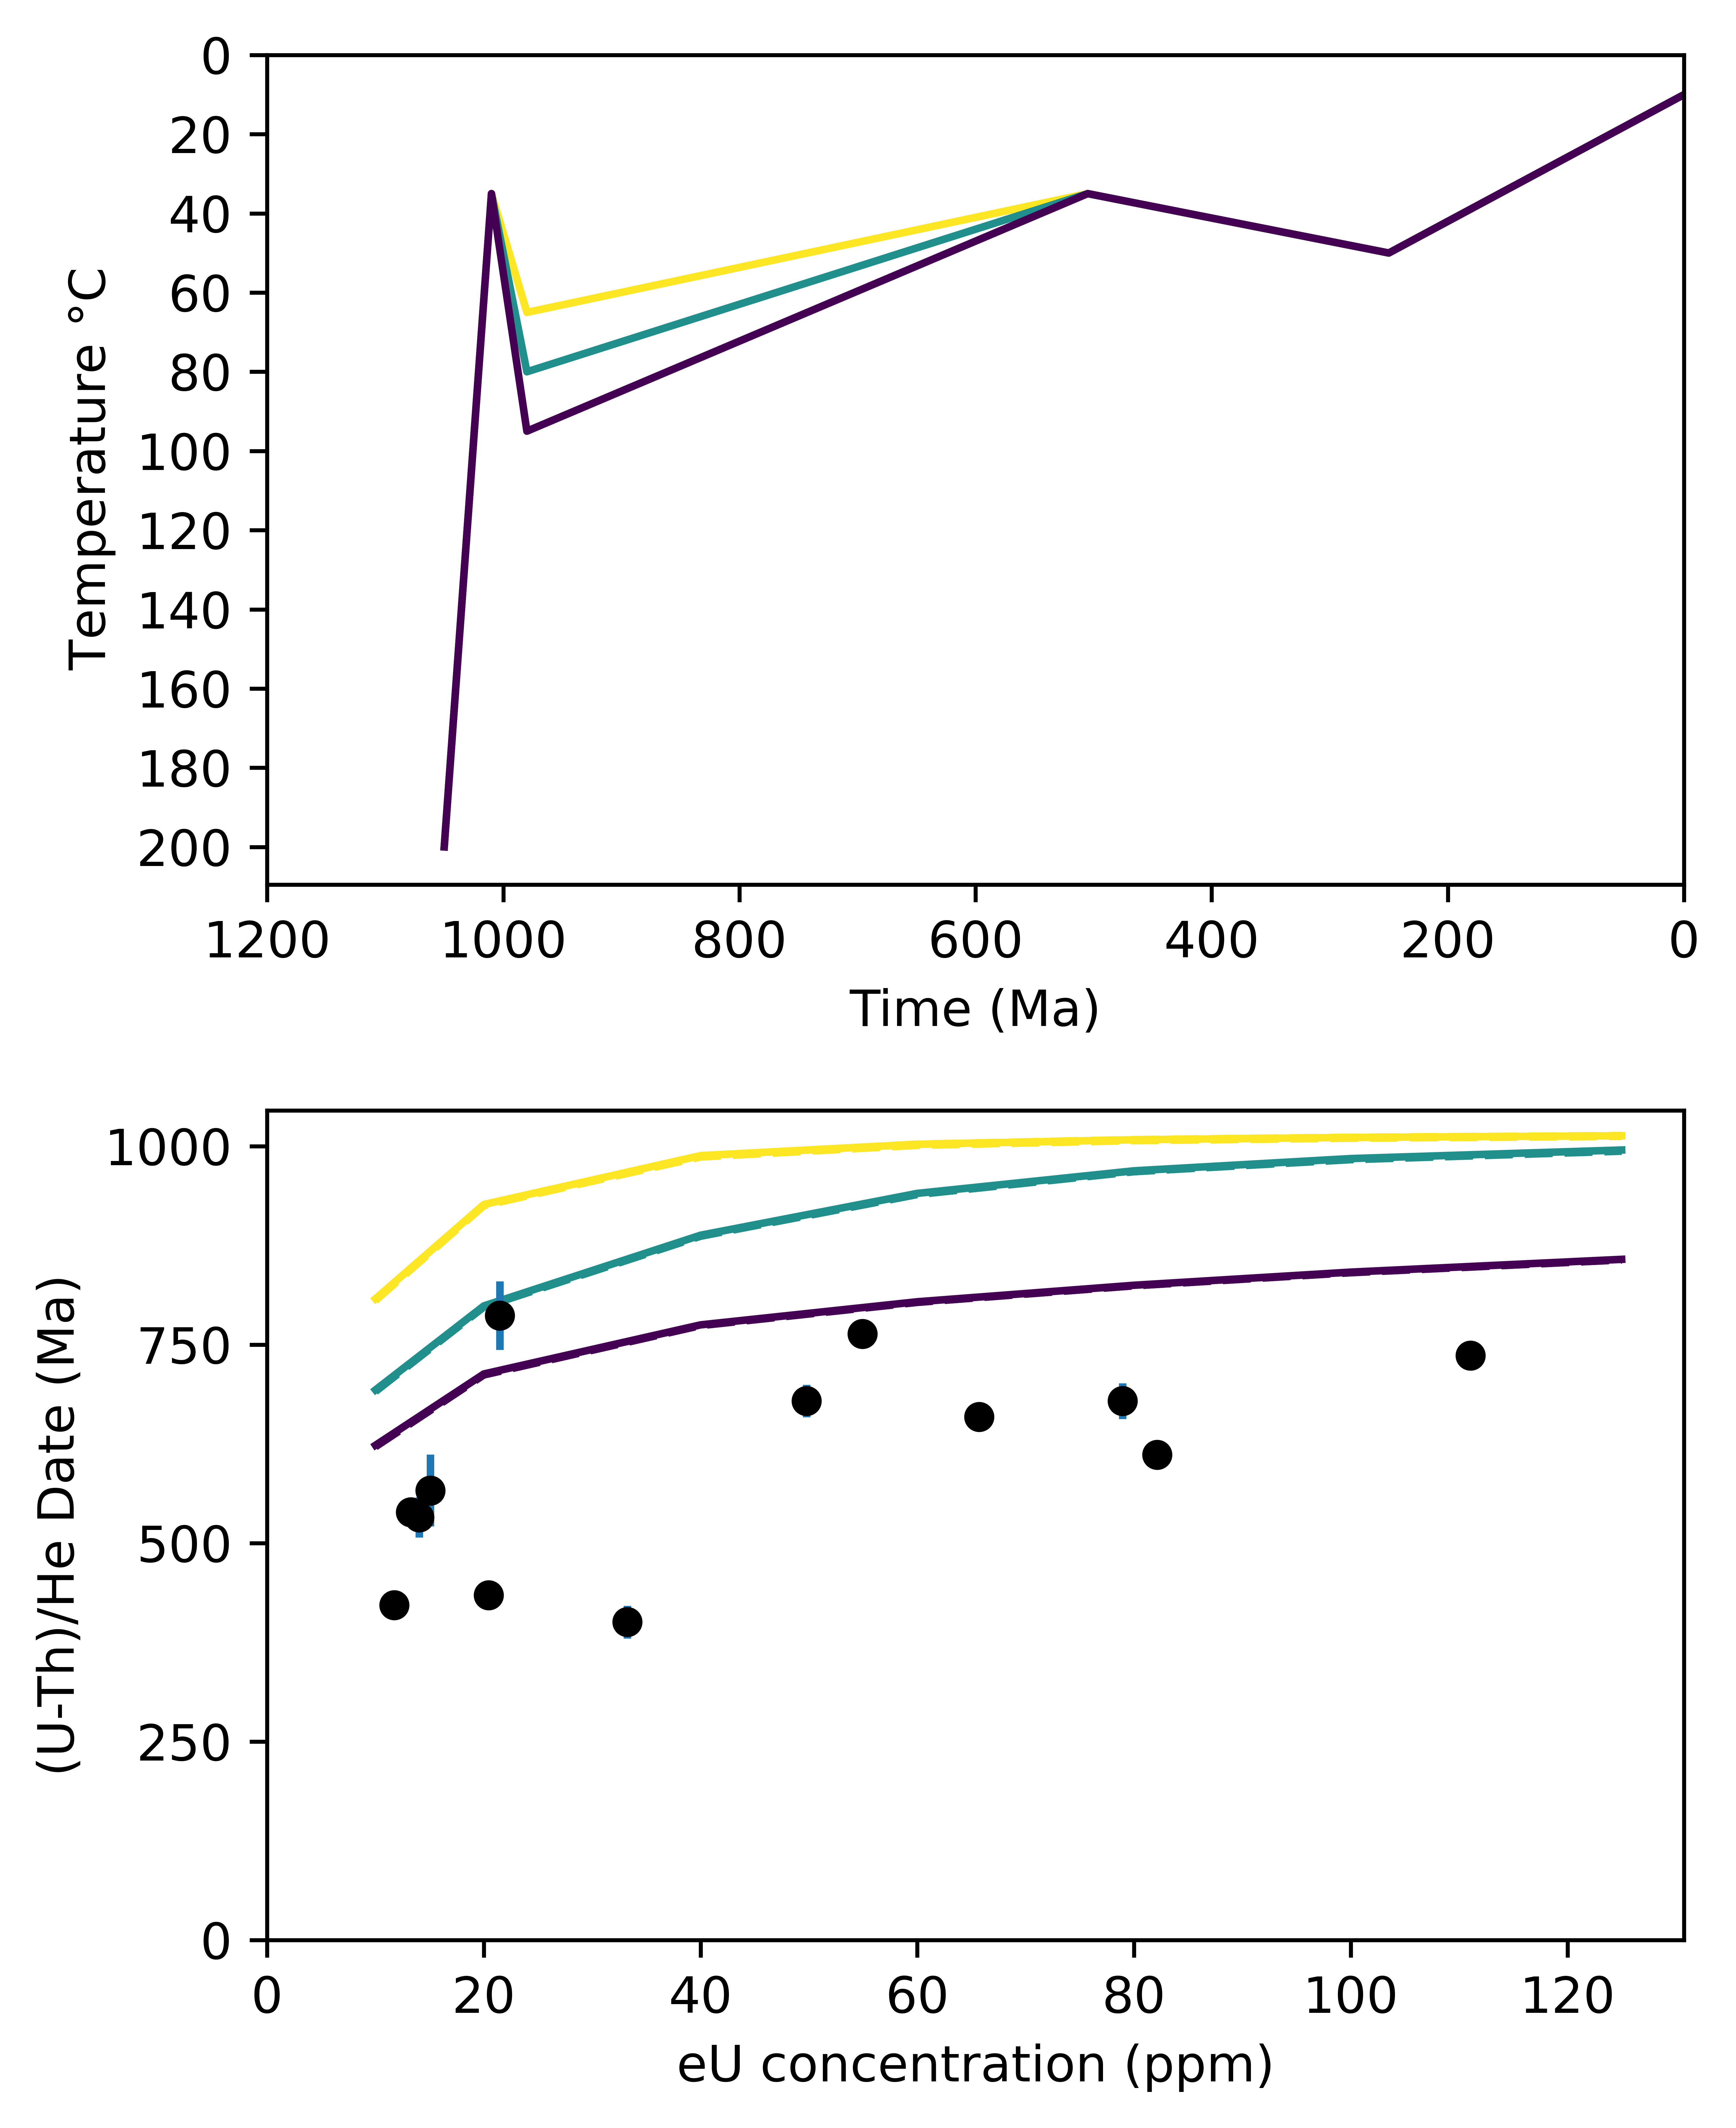

In [7]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_neo_heat,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7,colormap='viridis_r')

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(200,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_neo_heat.pdf',bbox_inches='tight')

#### Varied Neoproterozoic exhumation timing

The Neoproterozoic plateau in the AHe data is indicative of an interval of accelerated Neoproterozoic cooling compared to that shown in the scenarios above. With simplified scenarios we now adjust timing of Neoproterozoic cooling following early Neoproterozoic burial. The temperature at 980 Ma is held constant.

In [8]:
cooling_upper_1 = 850
cooling_lower_1 = 750
cooling_upper_2 = 750
cooling_lower_2 = 650
cooling_upper_3 = 650
cooling_lower_3 = 550
cooling_upper_4  = 600
cooling_lower_4 = Cambrian_age+1


tT_ap_neo_cool = np.array([[modern_age, modern_temp] * 4,
                           [Mesozoic_age, Mesozoic_temp] * 4,
                           [Cambrian_age, Cambrian_temp] * 4,
                           [cooling_lower_4,Cambrian_temp,cooling_lower_3,Cambrian_temp,cooling_lower_2,Cambrian_temp,cooling_lower_1,Cambrian_temp],
                           [cooling_upper_4,Bayfield_temp_3,cooling_upper_3,Bayfield_temp_3,cooling_upper_2,Bayfield_temp_3,cooling_upper_1,Bayfield_temp_3],
                           [Bayfield_age, Bayfield_temp_3] * 4,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * 4,
                           [rift_burial_age, rift_burial_temp] * 4])

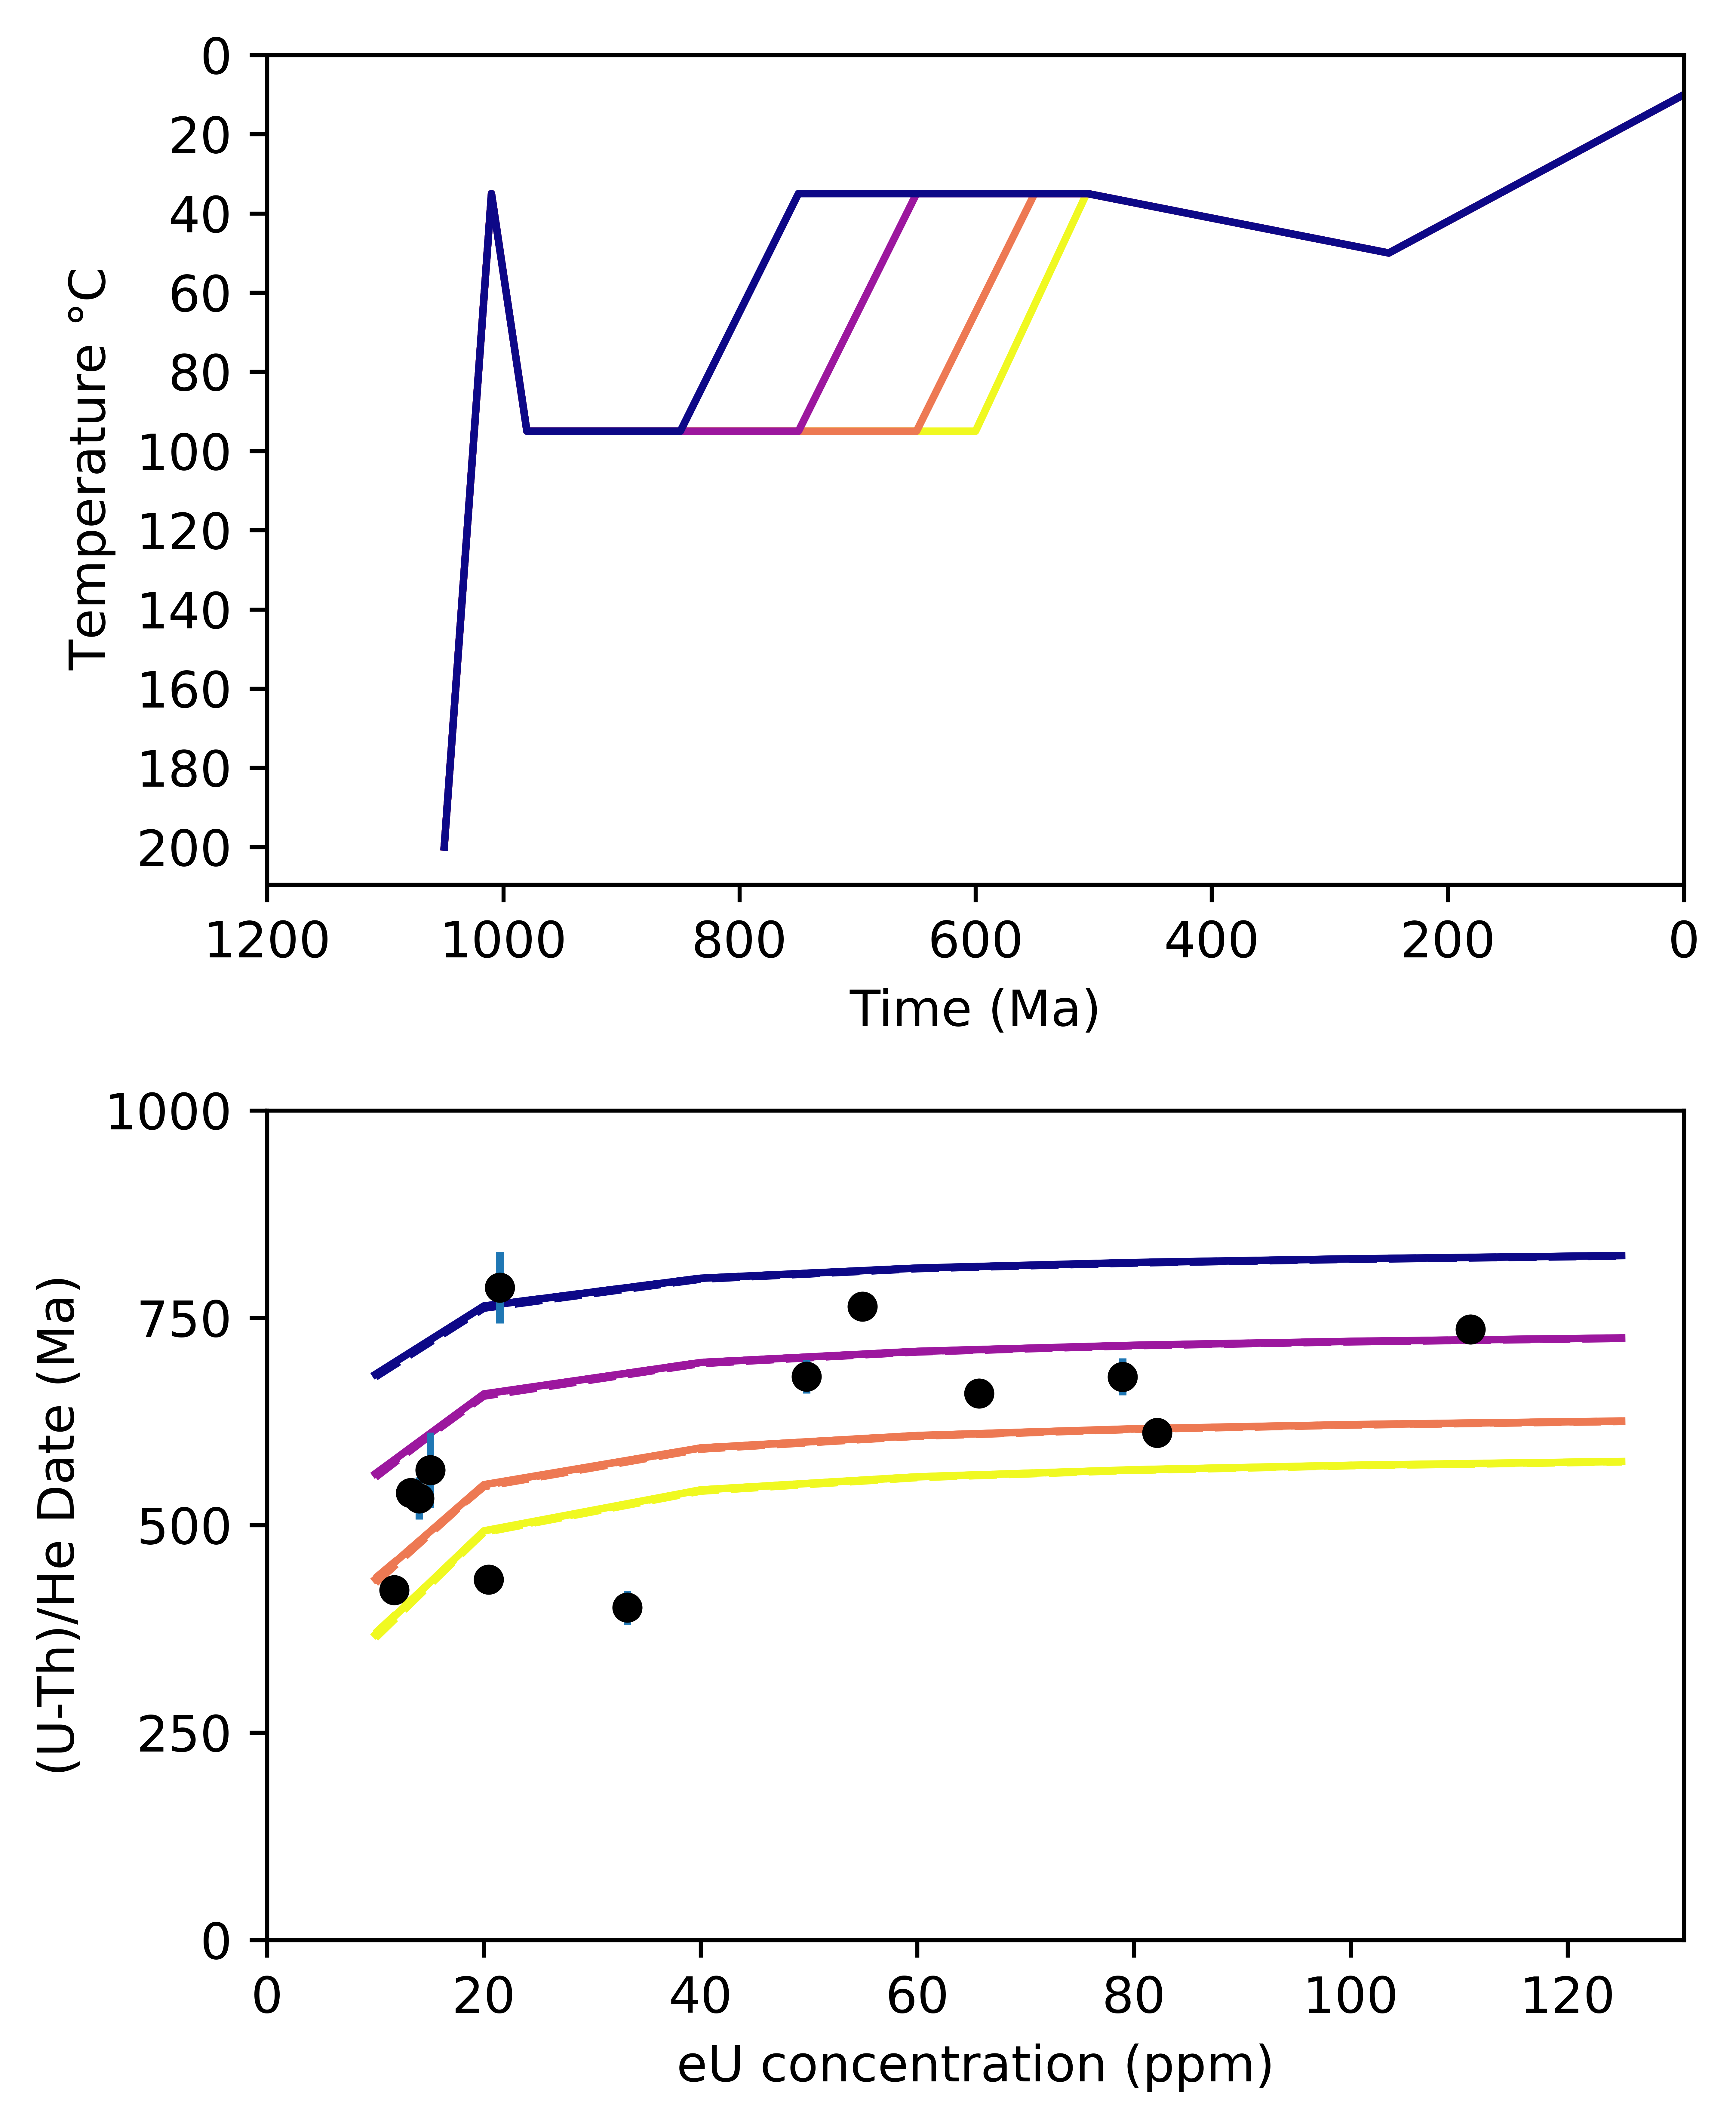

In [9]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_neo_cool,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7,colormap='plasma_r')

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(200,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_neo_cool.pdf',bbox_inches='tight')

#### Varied Phanerozoic heating

The next set of models tests simplified scenarios for the amount of reheating in the Phanerozoic associated with the accumulation of Paleozoic sedimentary rocks and compares these scenarios with the apatite data.

In [10]:
Mesozoic_temp_1 = 50
Mesozoic_temp_2 = 60
Mesozoic_temp_3 = 70
Mesozoic_temp_4 = 80
Mesozoic_temp_5 = 90

tT_ap_phan = np.array([[modern_age, modern_temp] * 5,
                           [Mesozoic_age, Mesozoic_temp_1, Mesozoic_age, Mesozoic_temp_2,
                            Mesozoic_age, Mesozoic_temp_3, Mesozoic_age, Mesozoic_temp_4, Mesozoic_age, Mesozoic_temp_5],
                           [Cambrian_age, Cambrian_temp] * 5,
                           [cooling_lower_2,Cambrian_temp] * 5,
                           [cooling_upper_2,Bayfield_temp_3] * 5,
                           [Bayfield_age, Bayfield_temp_3] * 5,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * 5,
                           [rift_burial_age, rift_burial_temp] * 5])

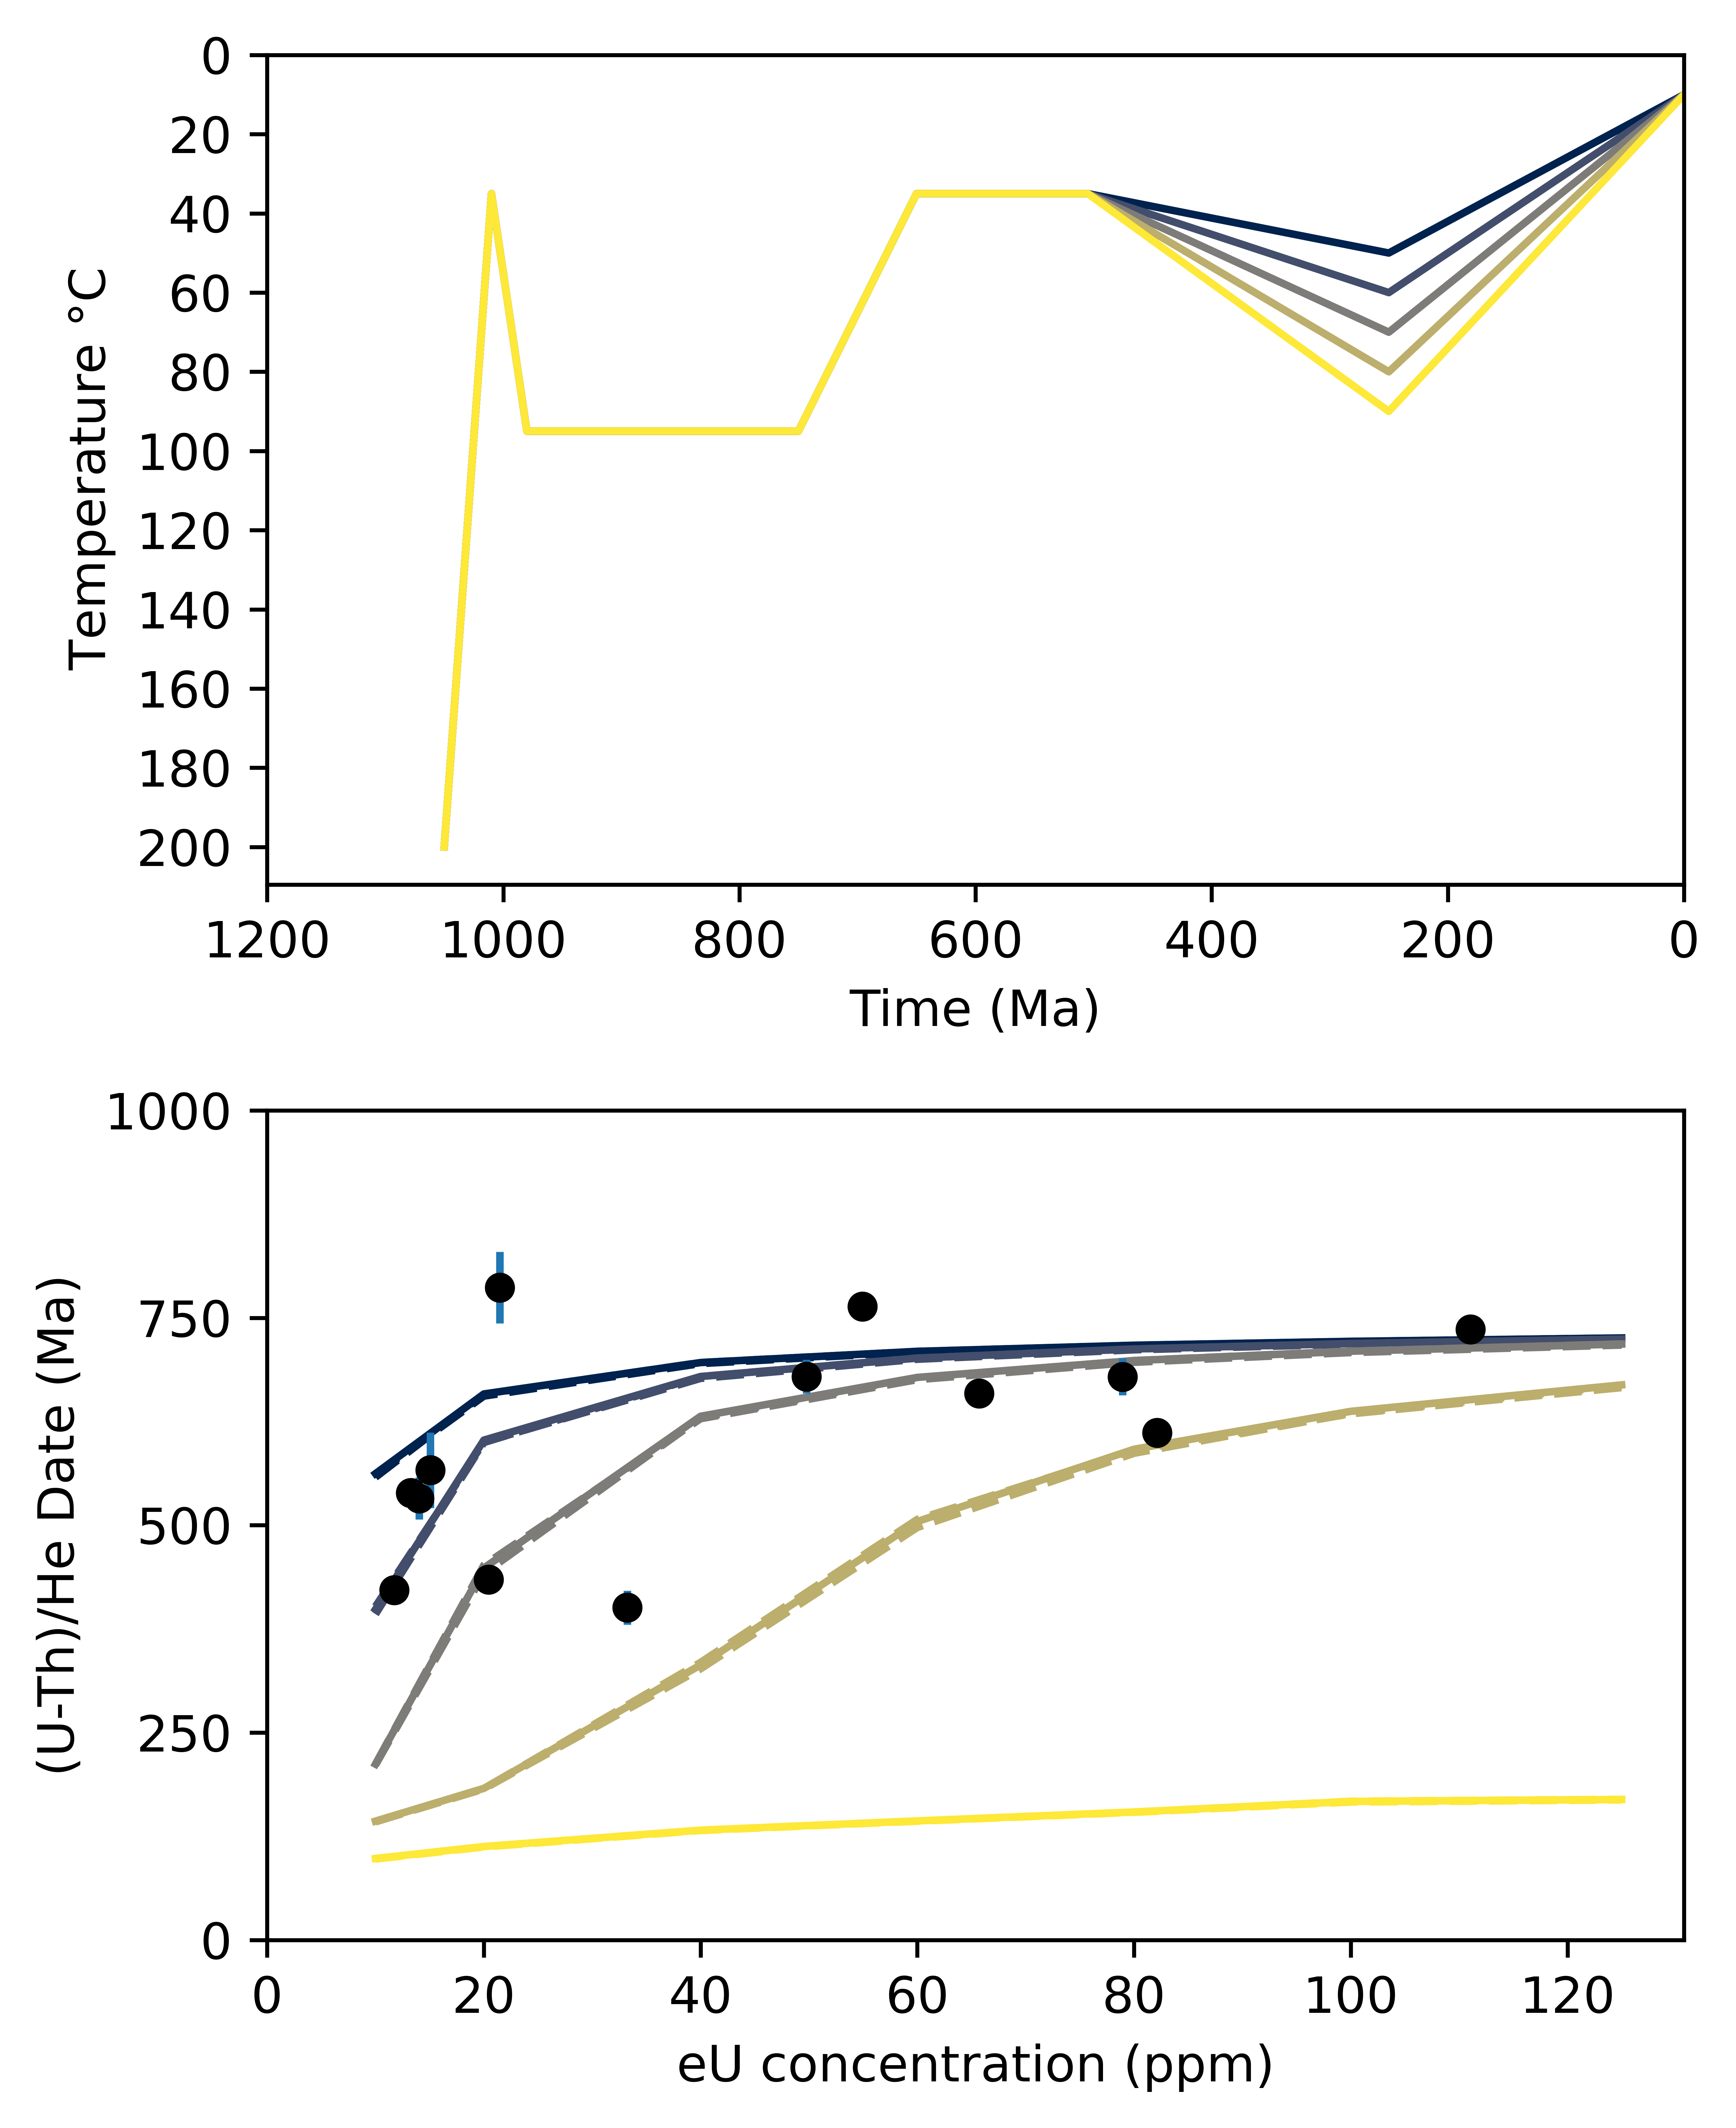

In [11]:
ap_paths = pyt.tT_model(ap_grain_in,tT_ap_phan,ap_obs_data)
ap_fig = ap_paths.forward(log2_nodes=7,colormap='cividis')

ax_1 = ap_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.xaxis.set_ticks(np.arange(1200,-1,-200))
ax_1.yaxis.set_ticks(np.arange(200,-1,-20))

ax_2 = ap_fig.axes[1]
ax_2.autoscale()
ax_2.xaxis.set_ticks(np.arange(0,140,20))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

ap_fig.savefig('figures/ap_forward_phan.pdf',bbox_inches='tight')

## Zircon forward models

For the ZHe data we need to consider a long time-temperature history that extends back through the Mesoproterozoic and Paleoproterozoic. In these models, there is a substantial amount of time spent a relatively low temperatures before 1100 Ma and the magnetitude of reheating at ca. 1050 Ma has more of an effect on the results in contrast with the AHe data.

In [12]:
Archean_age_1 = 2700
Archean_age_2 = 2300
Archean_age_3 = 1900
Archean_temp = 300

Paleoprot_age = 1875
Paleoprot_temp = 50

pre_rift_age = 1100
pre_rift_temp = 50

rift_burial_temp1 = 100
rift_burial_temp2 = 200
rift_burial_temp3 = 300
rift_burial_temp4 = 400

num_scenarios = 4

tT_zirc_meso_heat = np.array([[modern_age, modern_temp] * num_scenarios,
                           [Mesozoic_age, Mesozoic_temp_3] * num_scenarios,
                           [Cambrian_age, Cambrian_temp] * num_scenarios,
                           [cooling_lower_2,Cambrian_temp] * num_scenarios,
                           [cooling_upper_2,Bayfield_temp_3] * num_scenarios,
                           [Bayfield_age, Bayfield_temp_3] * num_scenarios,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * num_scenarios,
                           [rift_burial_age, rift_burial_temp1, rift_burial_age, rift_burial_temp2, rift_burial_age, rift_burial_temp3, rift_burial_age, rift_burial_temp4],
                           [pre_rift_age, pre_rift_temp] * num_scenarios,
                            [Paleoprot_age, Paleoprot_temp] * num_scenarios,
                            [Archean_age_1, Archean_temp] * num_scenarios])

tT_zirc_neo_cool = np.array([[modern_age, modern_temp] * num_scenarios,
                           [Mesozoic_age, Mesozoic_temp_3] * num_scenarios,
                           [Cambrian_age, Cambrian_temp] * num_scenarios,
                           [cooling_lower_4,Cambrian_temp,cooling_lower_3,Cambrian_temp,cooling_lower_2,Cambrian_temp,cooling_lower_1,Cambrian_temp],
                           [cooling_upper_4,Bayfield_temp_3,cooling_upper_3,Bayfield_temp_3,cooling_upper_2,Bayfield_temp_3,cooling_upper_1,Bayfield_temp_3],
                           [Bayfield_age, Bayfield_temp_3] * num_scenarios,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * num_scenarios,
                           [rift_burial_age, rift_burial_temp3] * num_scenarios,
                           [pre_rift_age, pre_rift_temp] * num_scenarios,
                            [Paleoprot_age, Paleoprot_temp] * num_scenarios,
                            [Archean_age_1, Archean_temp] * num_scenarios])

tT_zirc_phan = np.array([[modern_age, modern_temp] * 5,
                           [Mesozoic_age, Mesozoic_temp_1, Mesozoic_age, Mesozoic_temp_2, Mesozoic_age, Mesozoic_temp_3, Mesozoic_age, Mesozoic_temp_4, Mesozoic_age, Mesozoic_temp_5],
                           [Cambrian_age, Cambrian_temp] * 5,
                           [cooling_lower_2,Cambrian_temp] * 5,
                           [cooling_upper_2,Bayfield_temp_3] * 5,
                           [Bayfield_age, Bayfield_temp_3] * 5,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * 5,
                           [rift_burial_age, rift_burial_temp3] * 5,
                           [pre_rift_age, pre_rift_temp] * 5,
                            [Paleoprot_age, Paleoprot_temp] * 5,
                            [Archean_age_1, Archean_temp] * 5])

tT_zirc_paleo_cool = np.array([[modern_age, modern_temp] * 3,
                           [Mesozoic_age, Mesozoic_temp_3] * 3,
                           [Cambrian_age, Cambrian_temp] * 3,
                           [cooling_lower_2,Cambrian_temp] * 3,
                           [cooling_upper_2,Bayfield_temp_3] * 3,
                           [Bayfield_age, Bayfield_temp_3] * 3,
                           [rift_post_exhumation_age, rift_post_exhumation_temp] * 3,
                           [rift_burial_age, rift_burial_temp3] * 3,
                           [pre_rift_age, pre_rift_temp] * 3,
                            [Paleoprot_age, Paleoprot_temp] * 3,
                            [Archean_age_1, Archean_temp, Archean_age_2, Archean_temp, Archean_age_3, Archean_temp]])

#### Mesozoic (1100 Ma) reheating temperature tests

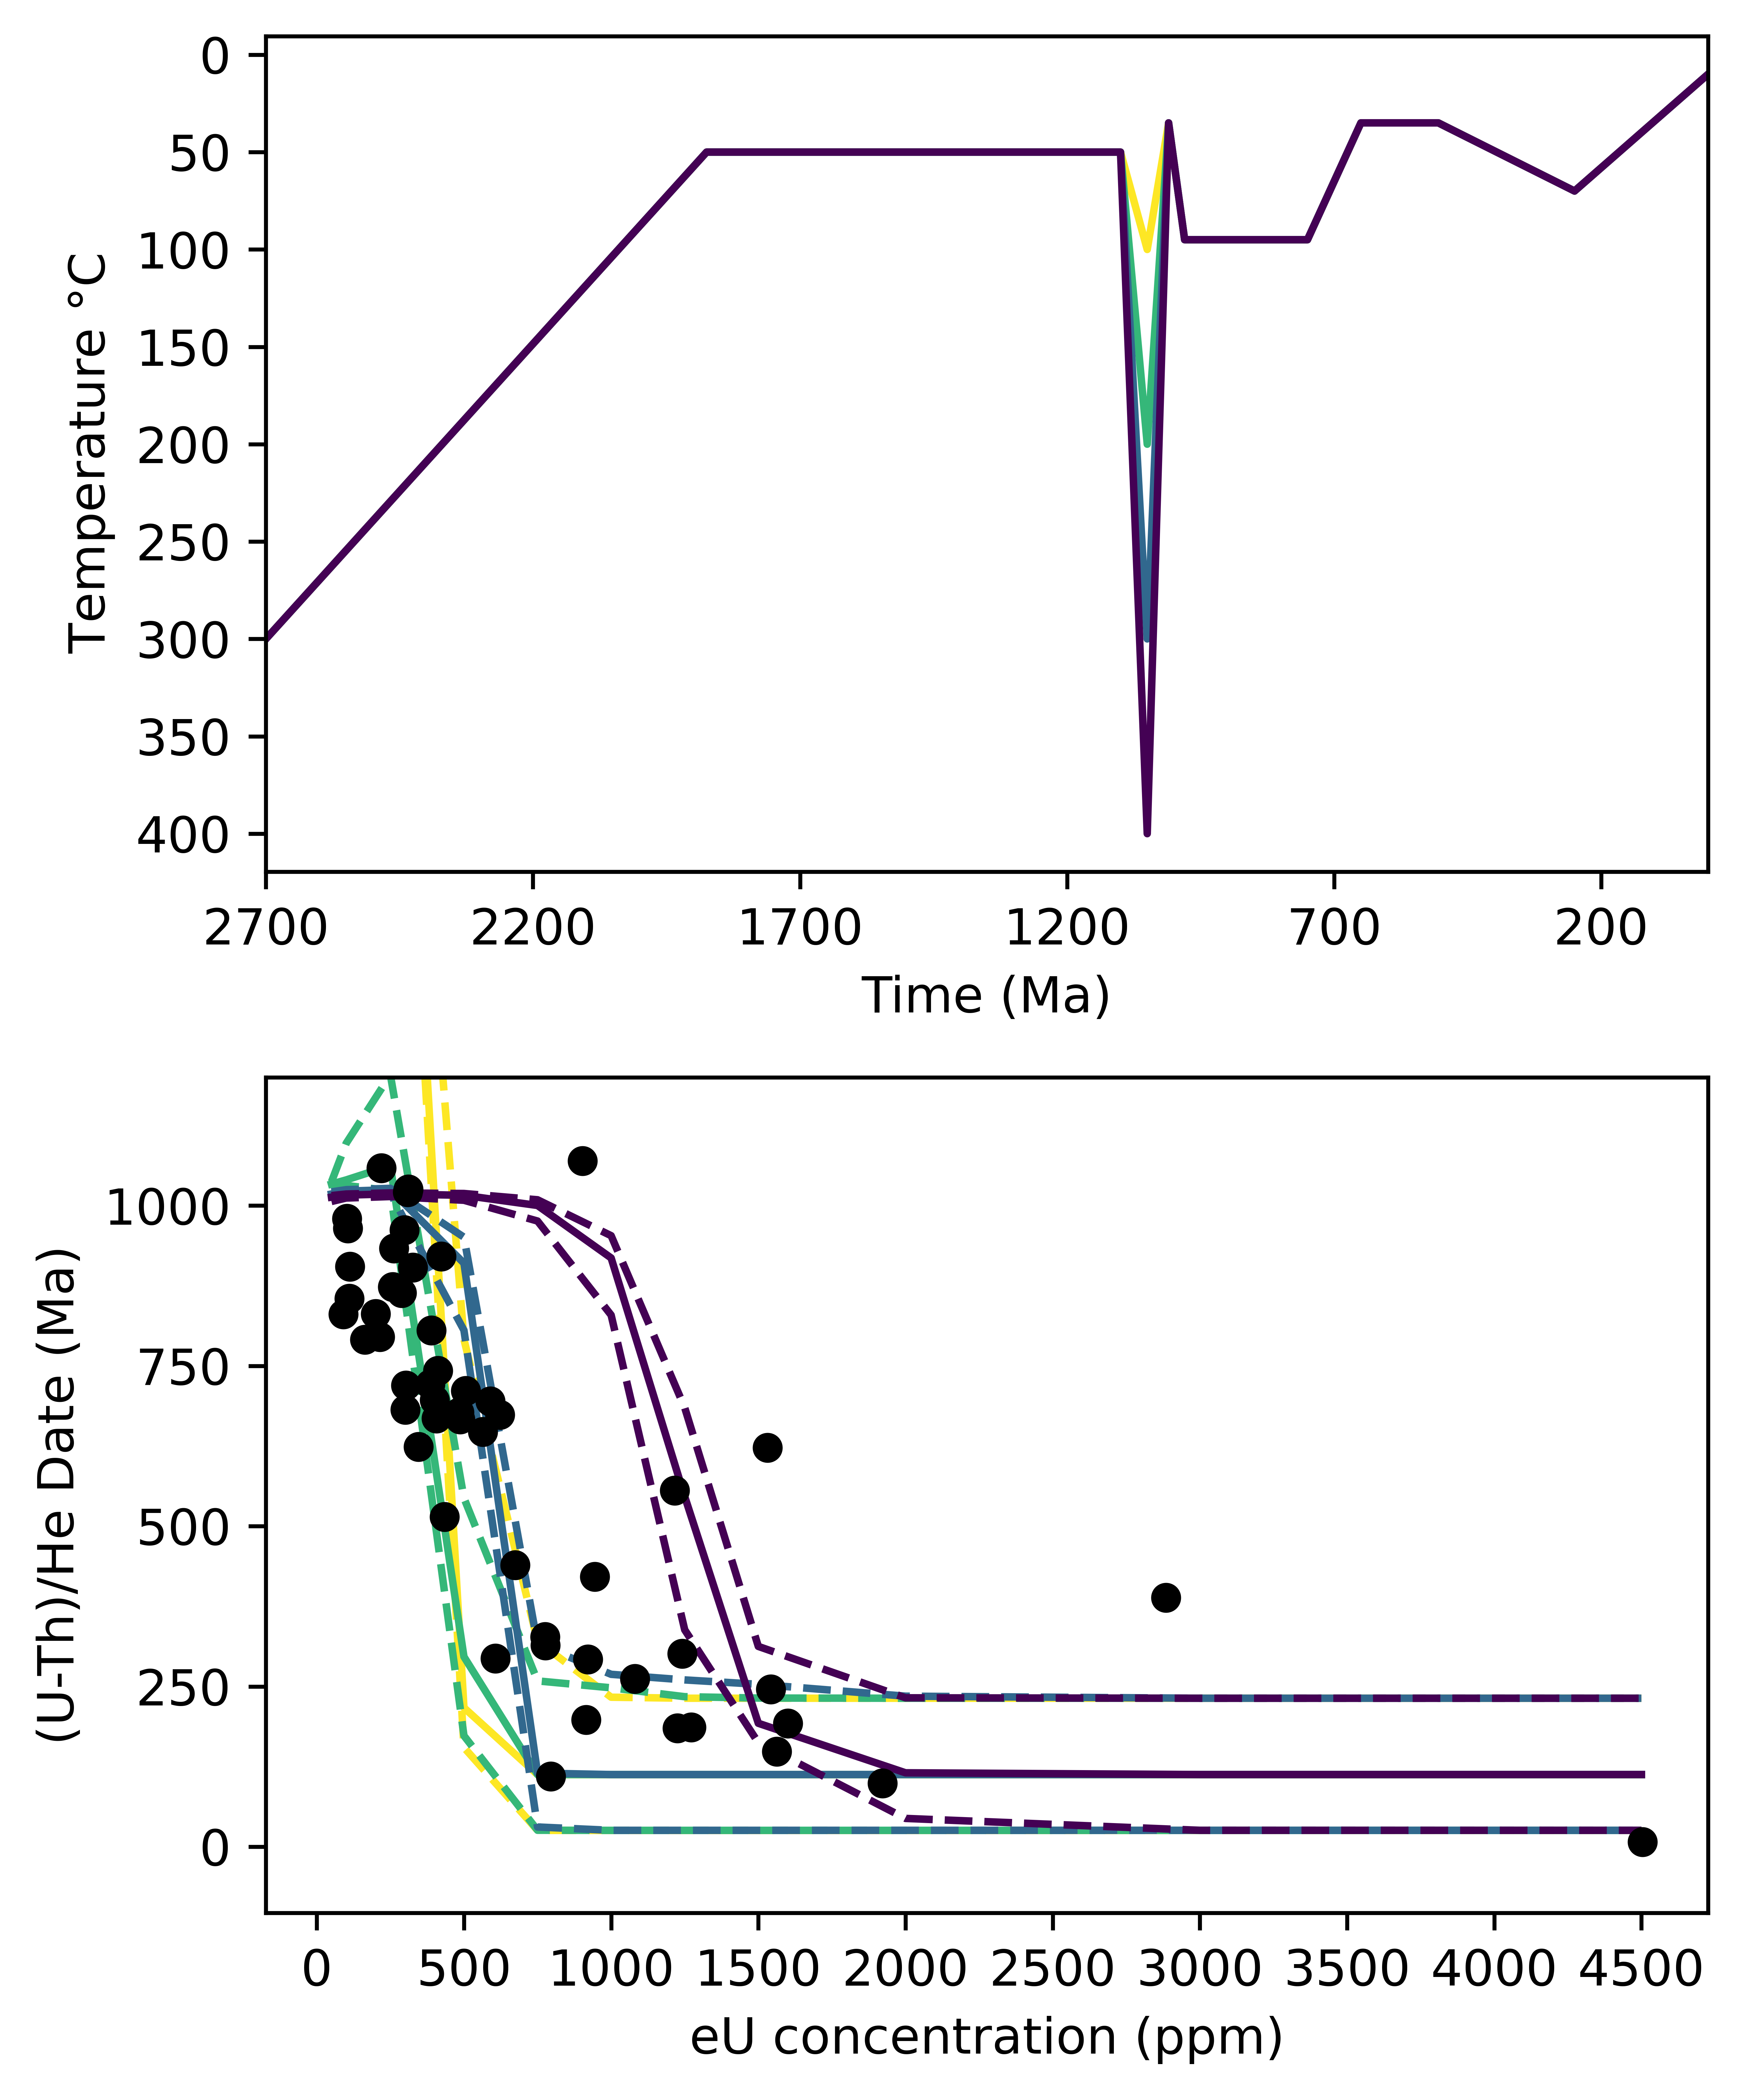

In [13]:
zirc_paths = pyt.tT_model(zirc_grain_in,tT_zirc_meso_heat,zirc_obs_data)
zirc_fig = zirc_paths.forward(log2_nodes=7, colormap='viridis_r')

ax_1 = zirc_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.set_xlim(left=2700)
ax_1.xaxis.set_ticks(np.arange(2700,-1,-500))
ax_1.yaxis.set_ticks(np.arange(400,-1,-50))

ax_2 = zirc_fig.axes[1]
ax_2.autoscale()
ax_2.set_ylim(top=1200)
ax_2.xaxis.set_ticks(np.arange(0,4501,500))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

zirc_fig.savefig('figures/zirc_forward_meso.pdf',bbox_inches='tight')

#### Test the timing of cooling in the Neoproterozoic 

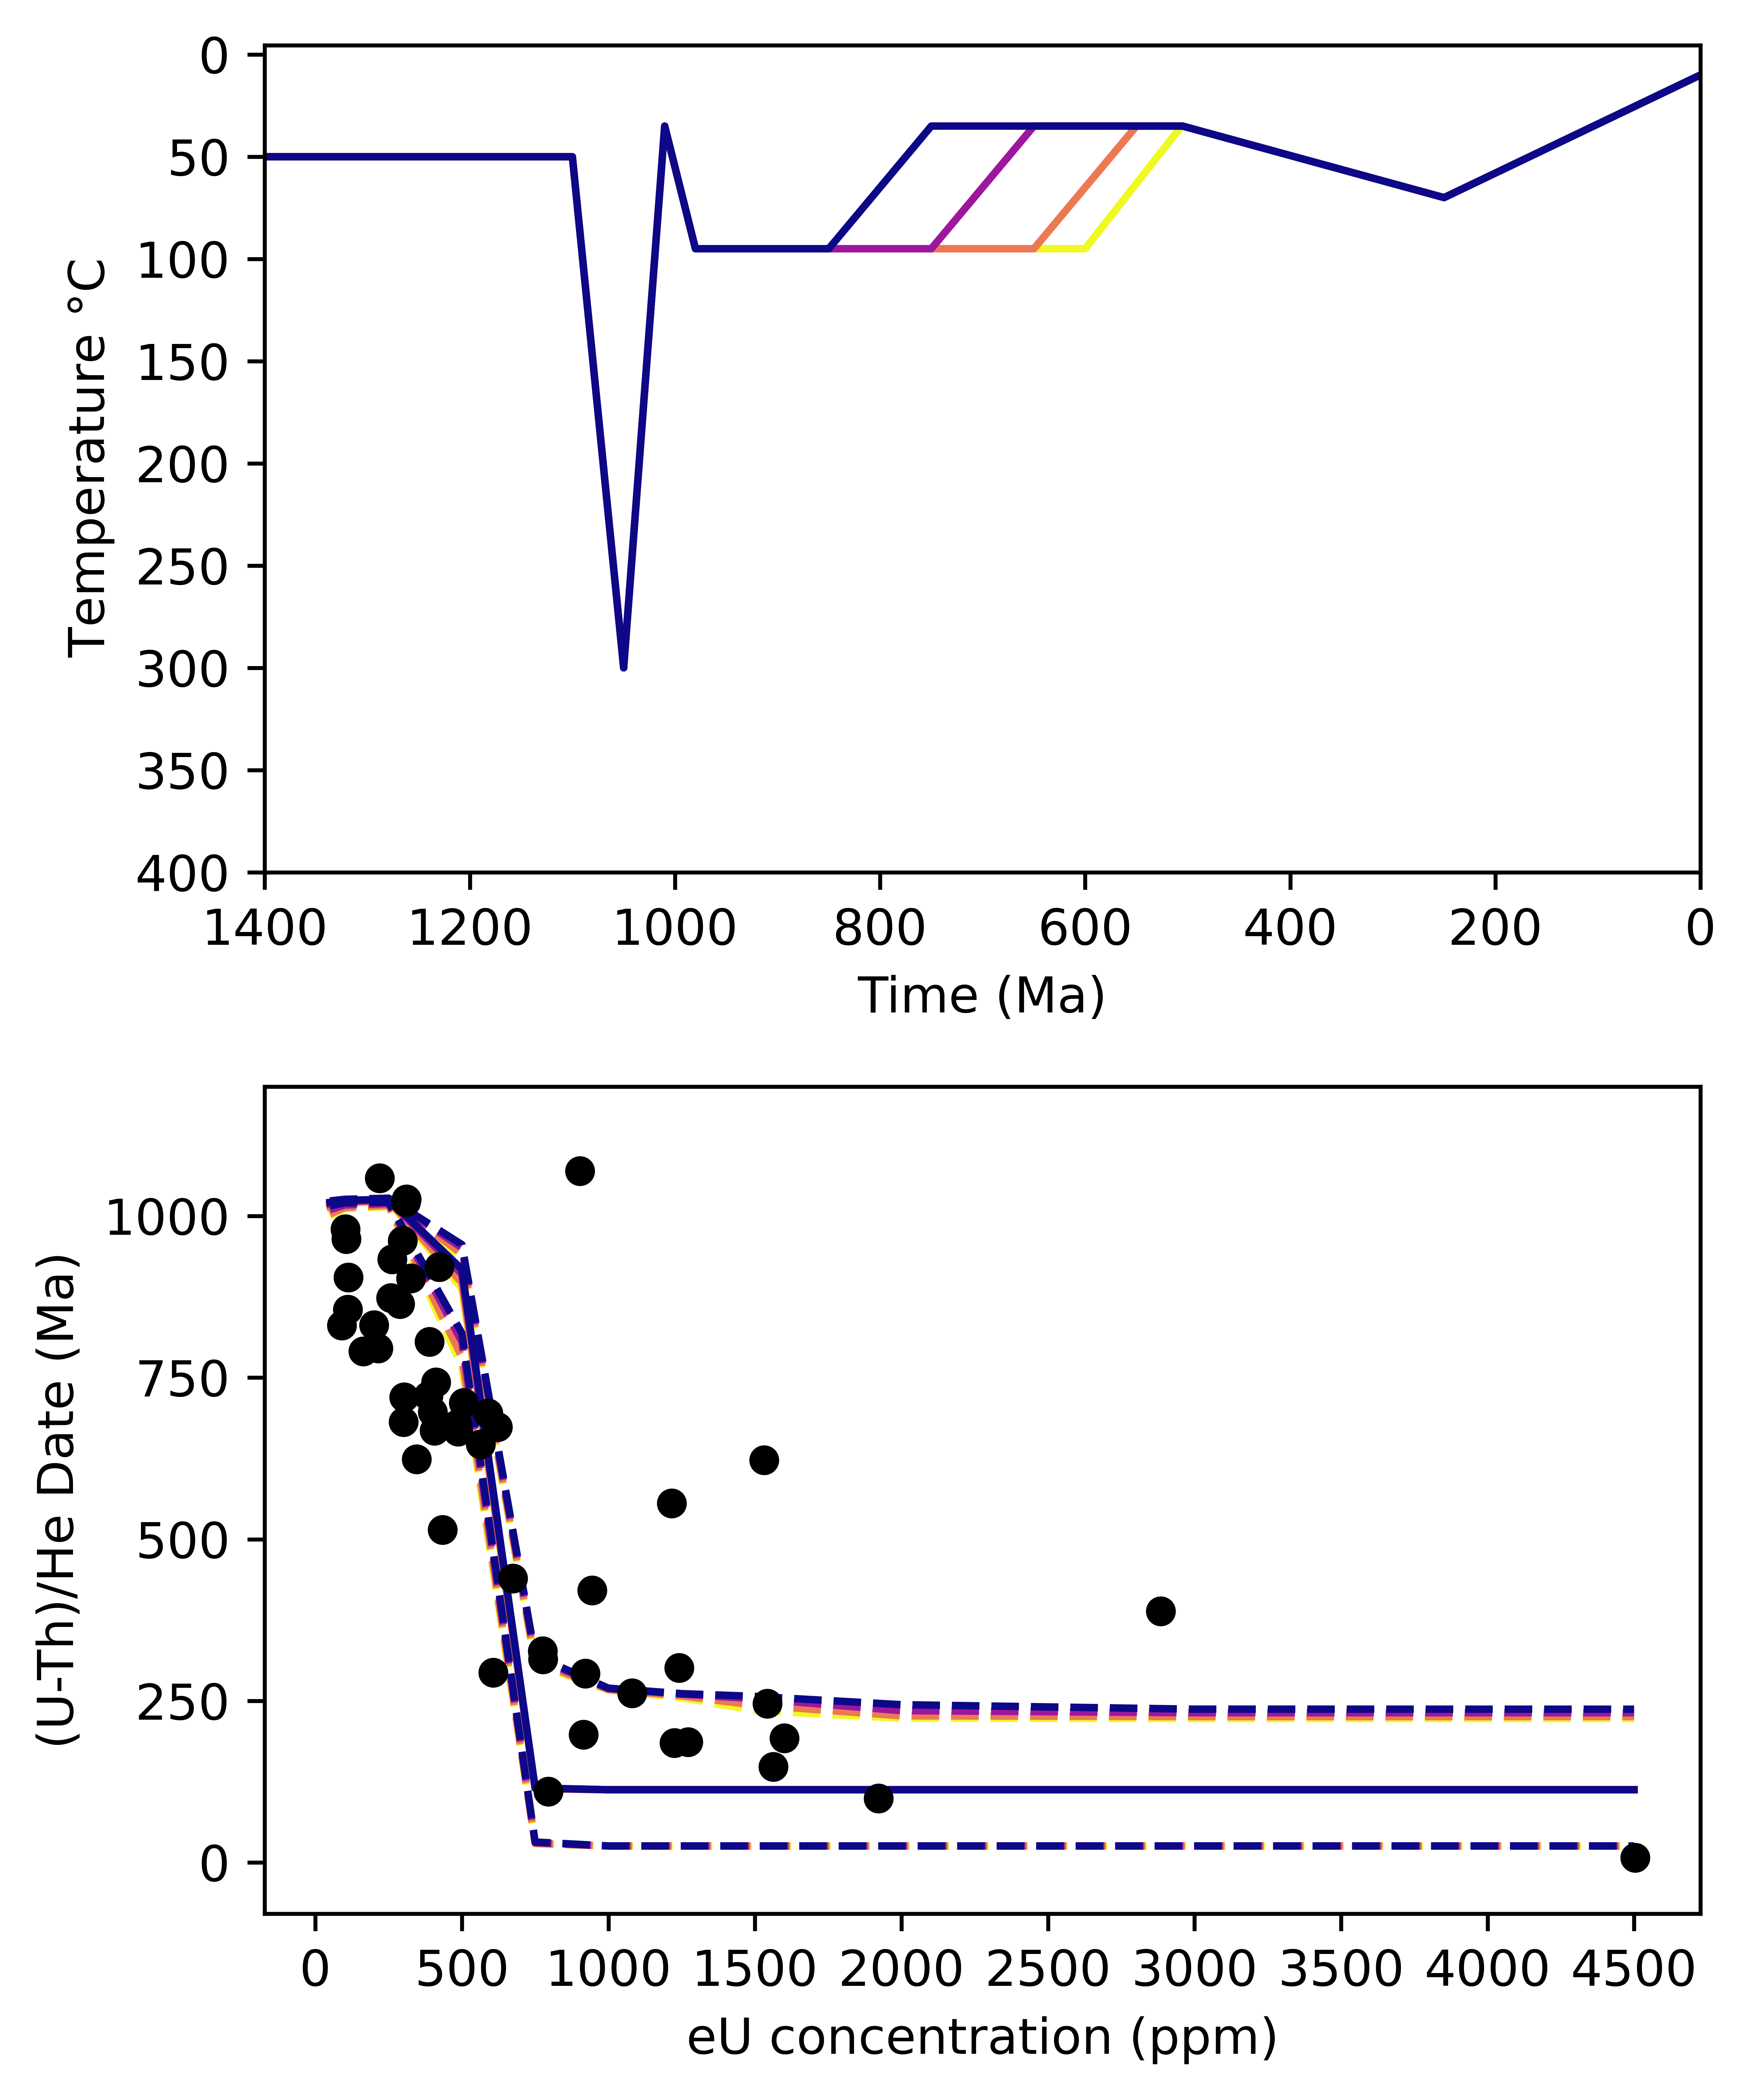

In [14]:
zirc_paths = pyt.tT_model(zirc_grain_in,tT_zirc_neo_cool,zirc_obs_data)
zirc_fig = zirc_paths.forward(log2_nodes=7,colormap='plasma_r')

ax_1 = zirc_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.set_xlim(left=1400)
ax_1.xaxis.set_ticks(np.arange(1400,-1,-200))
ax_1.yaxis.set_ticks(np.arange(400,-1,-50))

ax_2 = zirc_fig.axes[1]
ax_2.autoscale()
ax_2.set_ylim(top=1200)
ax_2.xaxis.set_ticks(np.arange(0,4501,500))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

zirc_fig.savefig('figures/zirc_forward_neo_cool.pdf',bbox_inches='tight')

#### Test the combined influence of reheating at 1100 Ma and in the Phanerozoic

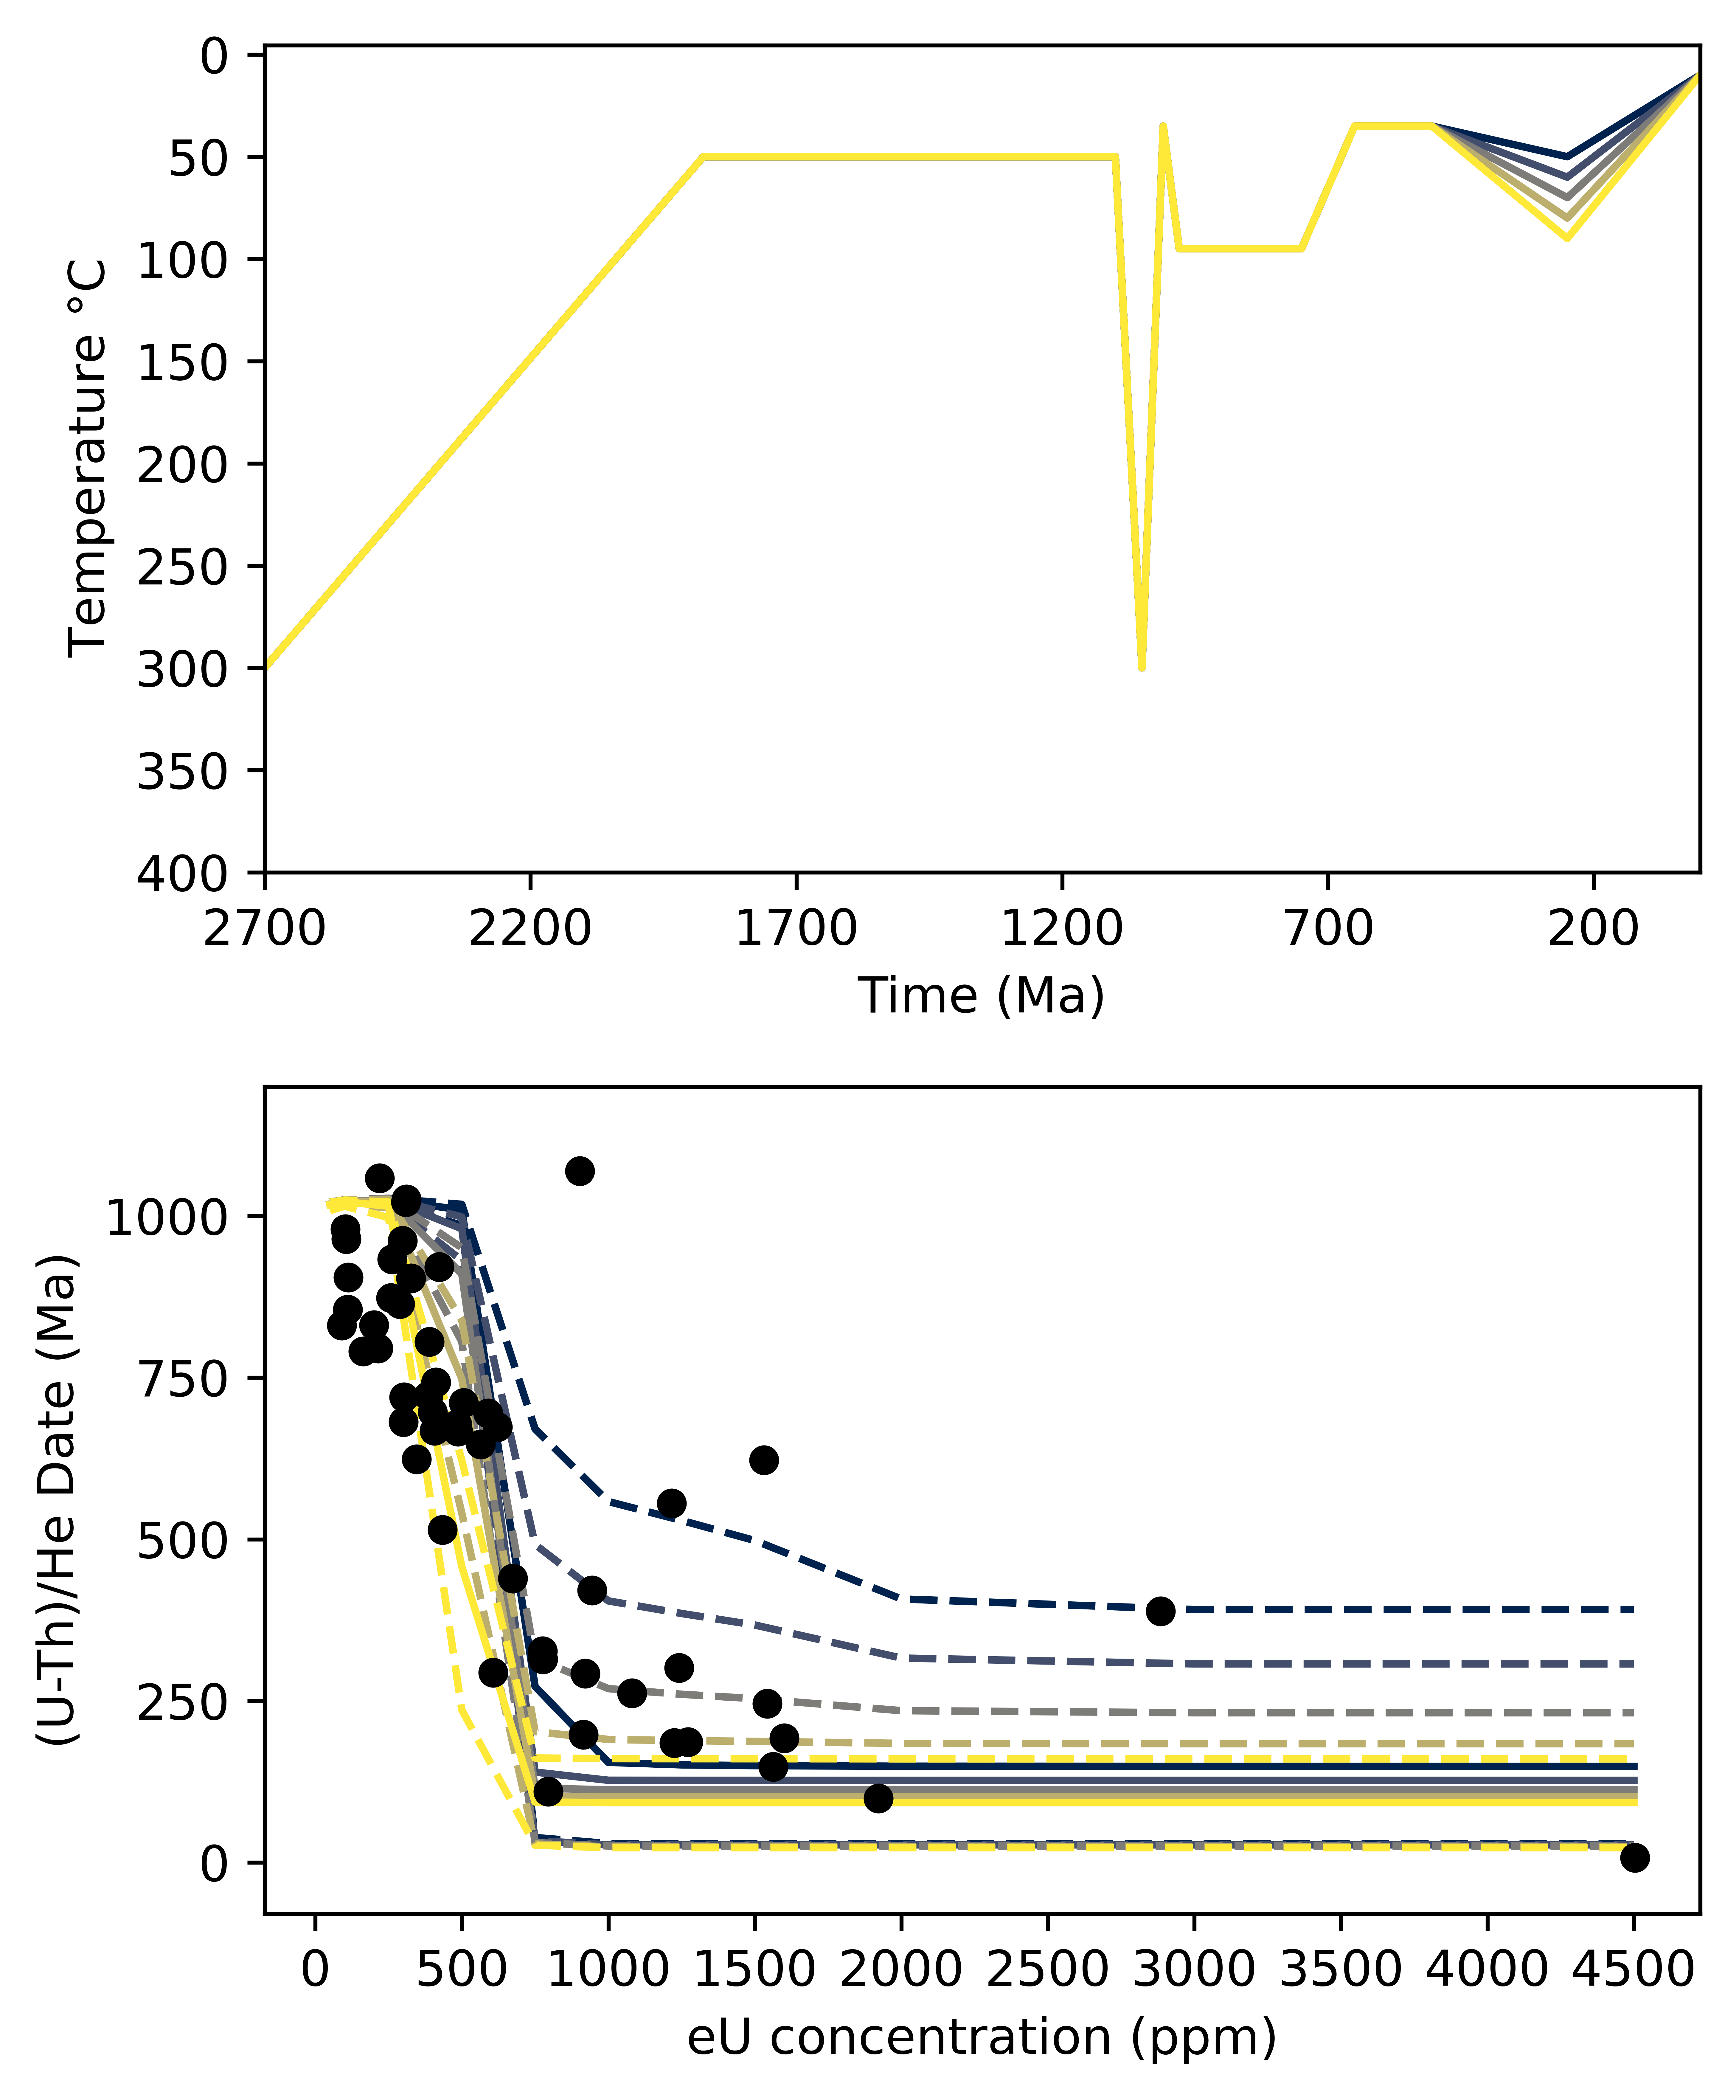

In [15]:
zirc_paths = pyt.tT_model(zirc_grain_in,tT_zirc_phan,zirc_obs_data)
zirc_fig = zirc_paths.forward(log2_nodes=7,colormap='cividis')

ax_1 = zirc_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.set_xlim(left=2700)
ax_1.xaxis.set_ticks(np.arange(2700,-1,-500))
ax_1.yaxis.set_ticks(np.arange(400,-1,-50))

ax_2 = zirc_fig.axes[1]
ax_2.autoscale()
ax_2.set_ylim(top=1200)
ax_2.xaxis.set_ticks(np.arange(0,4501,500))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

zirc_fig.savefig('figures/zirc_forward_phan.pdf',bbox_inches='tight')

#### Test the cooling trend prior to 1100 Ma

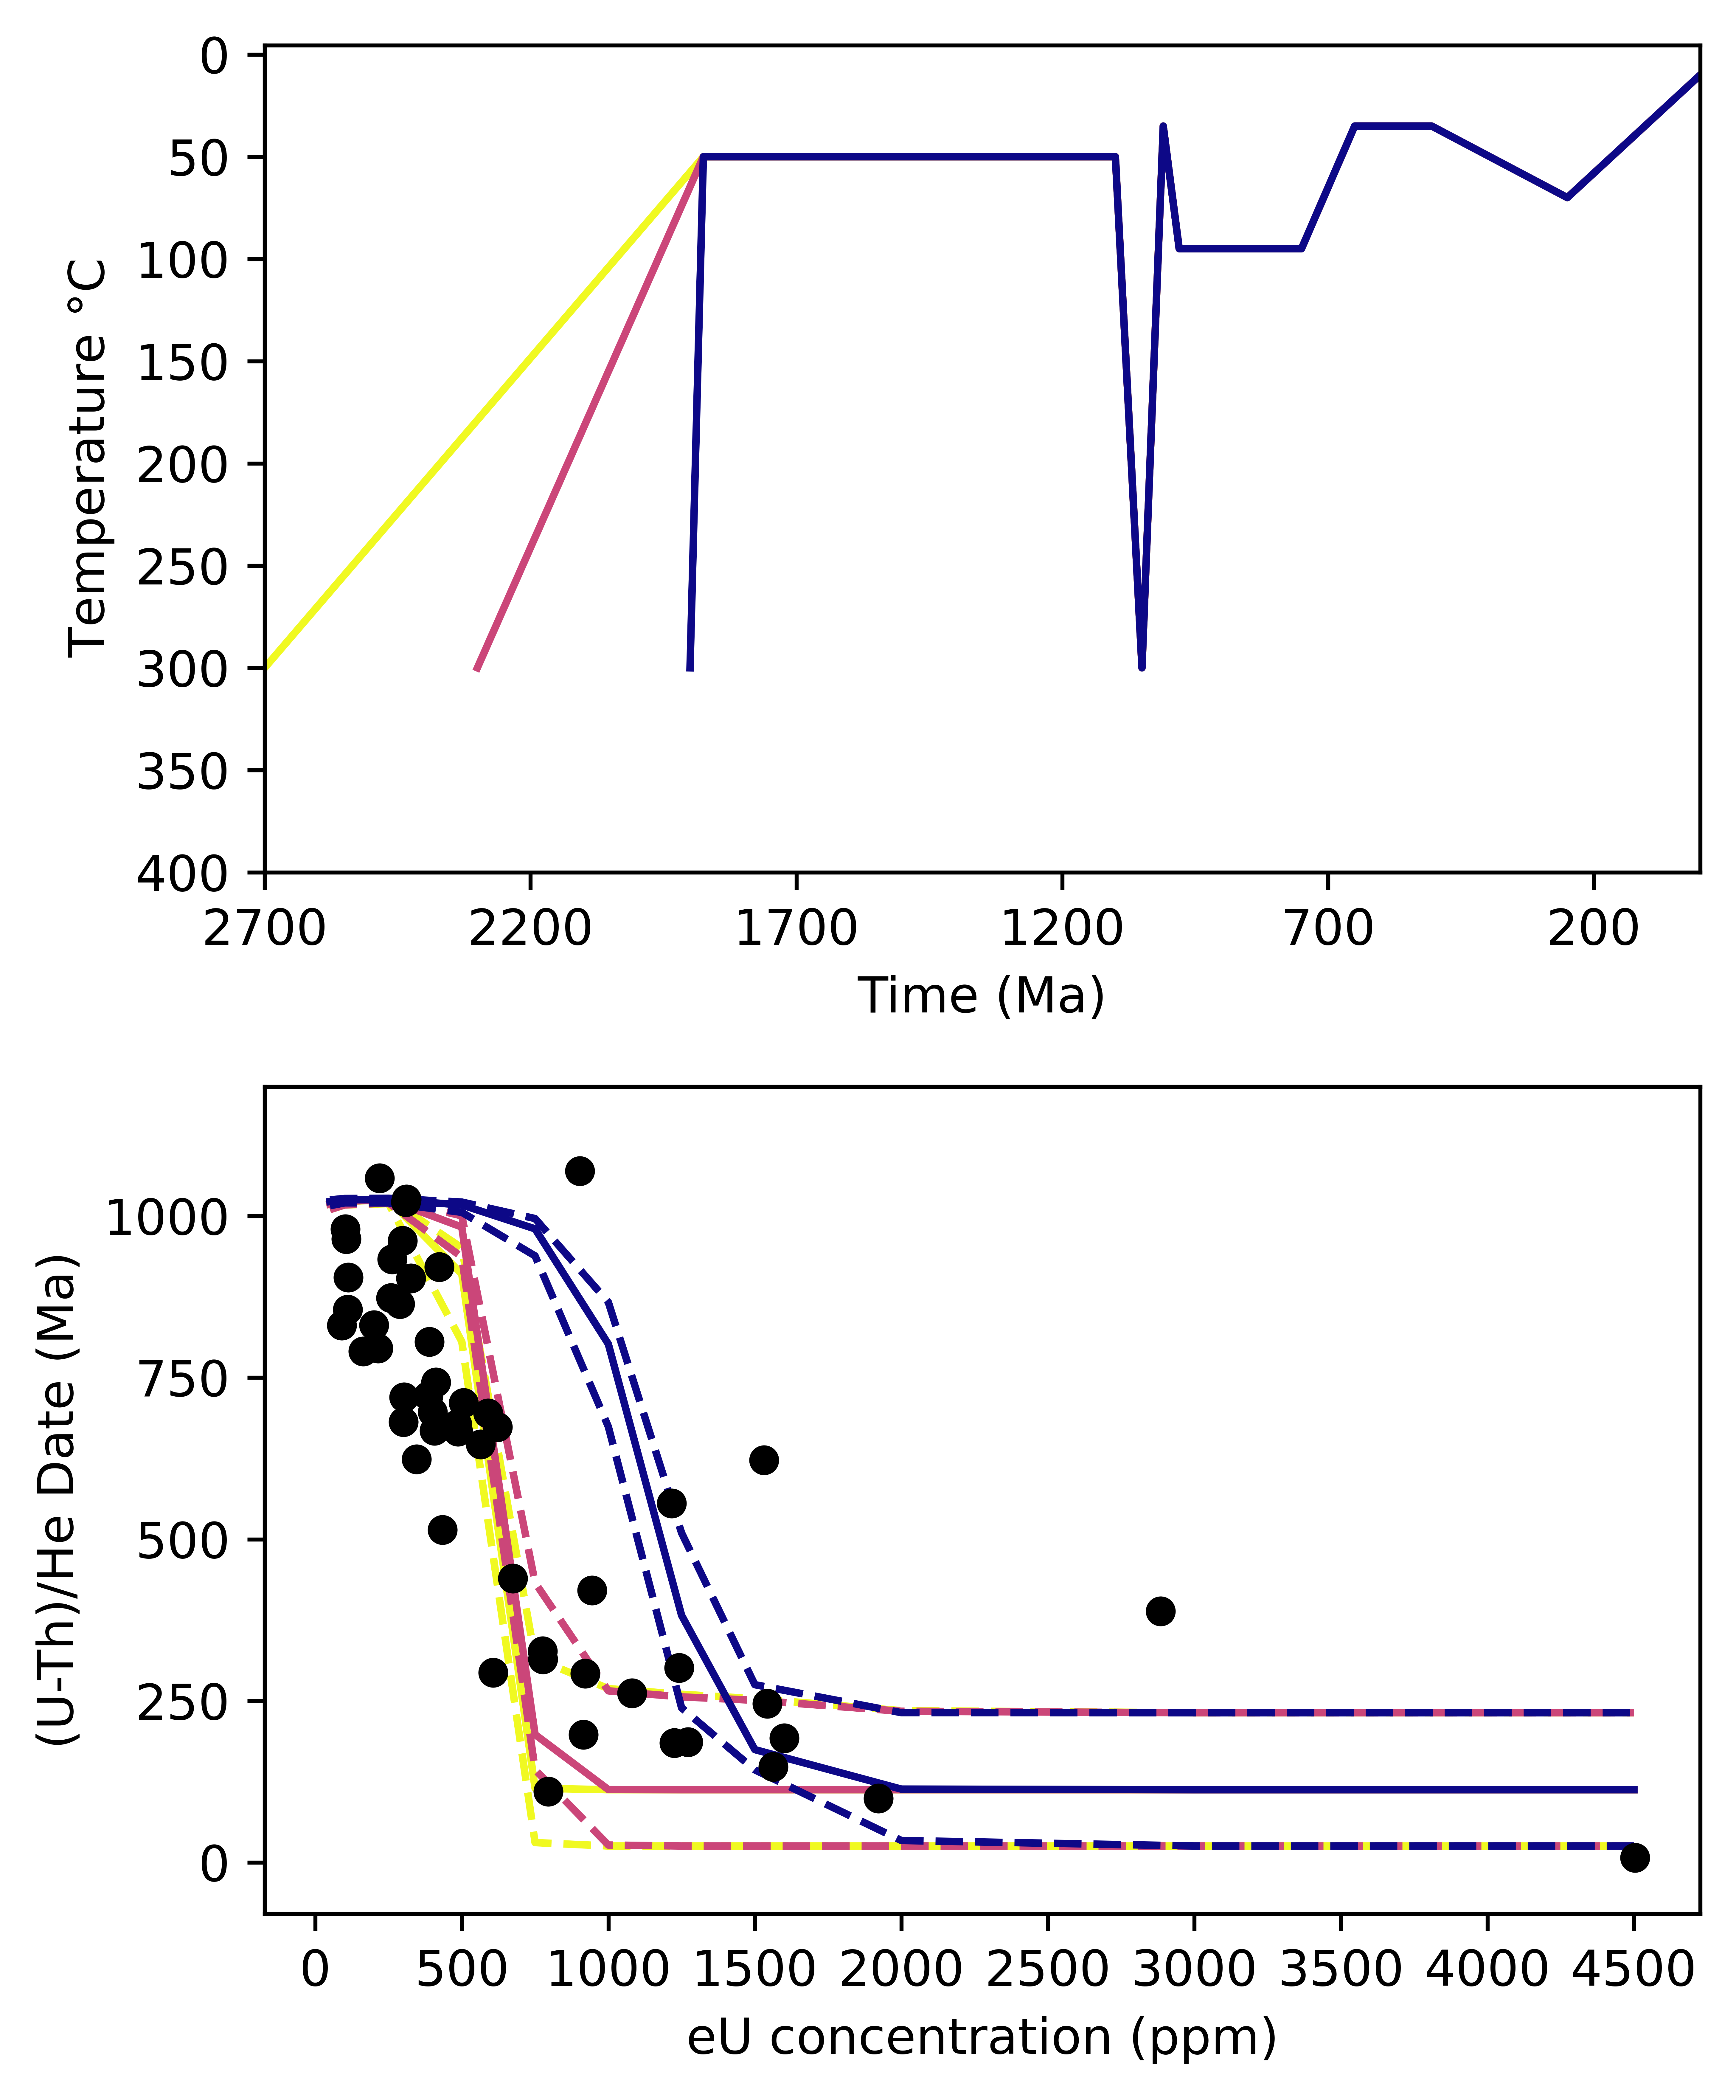

In [16]:
zirc_paths = pyt.tT_model(zirc_grain_in,tT_zirc_paleo_cool,zirc_obs_data)
zirc_fig = zirc_paths.forward(log2_nodes=7,colormap='plasma_r')

ax_1 = zirc_fig.axes[0]
ax_1.autoscale()
ax_1.set_xlim(right=0)
ax_1.set_xlim(left=2700)
ax_1.xaxis.set_ticks(np.arange(2700,-1,-500))
ax_1.yaxis.set_ticks(np.arange(400,-1,-50))

ax_2 = zirc_fig.axes[1]
ax_2.autoscale()
ax_2.set_ylim(top=1200)
ax_2.xaxis.set_ticks(np.arange(0,4501,500))
ax_2.yaxis.set_ticks(np.arange(0,1250,250))

zirc_fig.savefig('figures/zirc_forward_paleo_cool.pdf',bbox_inches='tight')